# 📊 EDA Pipeline — AWARE (Social Networking App Reviews)
**Aspect-Based Sentiment Analysis | Mobile App Reviews**

---
**Mục lục:**
- **Bước 0** — Đọc và làm sạch dữ liệu (AWARE đã ở dạng flat)
- **Bước 1** — Phân tích không gian nhãn (Label Space Analysis)
- **Bước 2** — Trực quan hoá phân bố: polarity, app, độ dài câu, số khía cạnh mỗi câu, rating, target ngầm định, biểu đồ tương tác
- **Bước 3** — Trích xuất ví dụ & minh hoạ cơ chế Mapping
- **Bước 4** — So sánh với Res16 và tổng kết (Data Quality Summary)

> **Lưu ý:** AWARE là single-file, không có split train/test riêng như Res16, và **không được dùng để huấn luyện** trong dự án này (chỉ EDA để so sánh miền dữ liệu).
> Dataset đã ở dạng flat (mỗi hàng = 1 câu + 1 opinion), không cần unpivot.

---
## 🔀 Bước 0 — Đọc & Làm sạch Dữ liệu

AWARE đã ở dạng **flat** (tidy format): mỗi hàng = 1 câu có 1 opinion gắn nhãn.
Câu được định danh bằng `sentence_id`; độ dài câu và số khía cạnh mỗi câu đều tính theo `sentence_id`.

In [51]:
# ── Cell 1: Import thư viện ───────────────────────────────────────────────
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# Style chung
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})
SENTIMENT_COLORS = {'positive': '#2E86AB', 'negative': '#C8553D'}   # cùng bảng màu với báo cáo
C_DARK, C_GOLD, C_GRAY = '#264653', '#E9C46A', '#8D99AE'
from matplotlib.colors import LinearSegmentedColormap
DIV_CMAP = LinearSegmentedColormap.from_list('neg_pos', ['#C8553D', '#F4F1EA', '#2E86AB'])

print('✅ Libraries loaded successfully.')

✅ Libraries loaded successfully.


In [52]:
# ── Cell 2: Đọc dữ liệu ───────────────────────────────────────────────────
PATH_AWARE = '../data/AWARE_Social_Networking.csv'

df_raw = pd.read_csv(PATH_AWARE)

print(f'Raw shape : {df_raw.shape}')
print(f'Columns   : {df_raw.columns.tolist()}')
print()
display(df_raw.head(3))

Raw shape : (3118, 14)
Columns   : ['domain', 'app', 'review_id', 'sentence_id', 'title', 'review', 'sentence', 'rating', 'is_opinion', 'category', 'term', 'from', 'to', 'sentiment']



,domain,app,review_id,sentence_id,title,review,sentence,rating,is_opinion,category,term,from,to,sentiment
0,social networking,whatsapp-messenger,aa65ef9e-27c0-496e-be43-089c1b186ff9,00437139-ab26-4f42-8050-8b464b0a90cd,Need video call through WhatsApp Web,I like WhatsApp to talk to friends that aren’t...,I just drained about 15-20 percent of my phone...,4,True,efficiency,video call,67.0,77.0,negative
1,social networking,discord,fb8b4293-2956-446e-9181-02ed3ceff8ac,007ecad5-2bd1-47de-b94c-4c367b7e2c59,Sharing Screens,"As a mobile user, it is unfortunate that we ca...","On an iPad Pro, I would honestly expect somewa...",4,True,effectiveness,share,52.0,57.0,negative
2,social networking,teamspeak-3,b9c54729-6dea-44da-877e-f1891cf977c6,0097e9d8-fe91-45d1-b66f-3e6cac36459e,Great!!,Does everything the desktop app does! Slight b...,Would be awesome if you could press the volume...,5,True,usability,volume,41.0,47.0,negative


In [53]:
# ── Cell 3: Làm sạch & chuẩn bị DataFrame ─────────────────────────────────
df = df_raw.copy()

# Chuẩn hoá tên cột sentiment → polarity (nhất quán với notebook res16)
df = df.rename(columns={'sentiment': 'polarity'})

# Chỉ giữ các opinion hợp lệ (is_opinion == True)
# (Theo metadata, toàn bộ dataset là is_opinion=True, nhưng kiểm tra cho chắc)
before = len(df)
df = df[df['is_opinion'] == True].reset_index(drop=True)
print(f'Rows sau khi filter is_opinion=True: {len(df):,} (loại bỏ {before - len(df)} hàng)')

# Thêm cột text_len cho phân tích
df['text_len'] = df['sentence'].str.len()

# Kiểm tra missing values
missing = df[['sentence', 'category', 'polarity', 'app']].isna().sum()
print('\nMissing values:')
print(missing)
print(f'\n✅ Cleaned dataset shape: {df.shape}')

Rows sau khi filter is_opinion=True: 3,118 (loại bỏ 0 hàng)

Missing values:
sentence    0
category    0
polarity    0
app         0
dtype: int64

✅ Cleaned dataset shape: (3118, 15)


In [54]:
# ── Cell 4: Tổng quan nhanh ───────────────────────────────────────────────
print('📋 AWARE Dataset Overview:')
overview = pd.DataFrame({
    'Metric': [
        'Total opinions (rows)',
        'Unique reviews',
        'Unique sentences',
        'Unique apps',
        'Unique categories',
        'Unique polarities'
    ],
    'Value': [
        f'{len(df):,}',
        f'{df["review_id"].nunique():,}',
        f'{df["sentence_id"].nunique():,}',
        f'{df["app"].nunique()}',
        f'{df["category"].nunique()}',
        f'{df["polarity"].nunique()}'
    ]
})
display(overview.style.hide(axis='index'))

📋 AWARE Dataset Overview:


Metric,Value
Total opinions (rows),"3,118"
Unique reviews,"1,615"
Unique sentences,"2,965"
Unique apps,6
Unique categories,9
Unique polarities,2


---
## 🏷️ Bước 1 — Phân tích Không gian Nhãn (Label Space Analysis)

In [55]:
# ── Cell 5: Tổng quan không gian nhãn ─────────────────────────────────────
unique_categories = sorted(df['category'].unique())
unique_polarities = sorted(df['polarity'].unique())
unique_apps       = sorted(df['app'].unique())

label_combos = df.groupby(['category', 'polarity']).size().reset_index(name='count')

print('=' * 55)
print('      LABEL SPACE SUMMARY — AWARE')
print('=' * 55)
print(f'  Unique Categories                : {len(unique_categories)}')
print(f'  Unique Polarities                : {len(unique_polarities)}')
print(f'  Max theoretical labels CxP       : {len(unique_categories)*len(unique_polarities)}')
print(f'  Actual label combos observed     : {len(label_combos)}')
print(f'  Unique Apps                      : {len(unique_apps)}')
print('=' * 55)
print(f'\n  Categories: {unique_categories}')
print(f'  Polarities: {unique_polarities}')
print(f'  Apps      : {unique_apps}')

      LABEL SPACE SUMMARY — AWARE
  Unique Categories                : 9
  Unique Polarities                : 2
  Max theoretical labels CxP       : 18
  Actual label combos observed     : 18
  Unique Apps                      : 6

  Categories: ['cost', 'effectiveness', 'efficiency', 'enjoyability', 'general', 'reliability', 'safety', 'security', 'usability']
  Polarities: ['negative', 'positive']
  Apps      : ['discord', 'facebook', 'free-tone-calling-texting', 'teamspeak-3', 'threema-the-secure-messenger', 'whatsapp-messenger']


In [56]:
# ── Cell 6: Bảng tần suất nhãn theo Category × Polarity ───────────────────
label_freq = (
    df.groupby(['category', 'polarity'])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=['positive', 'negative'], fill_value=0)
)
label_freq['TOTAL'] = label_freq.sum(axis=1)
label_freq = label_freq.sort_values('TOTAL', ascending=False)
label_freq['pos_rate%'] = (label_freq['positive'] / label_freq['TOTAL'] * 100).round(1)

print('📊 AWARE — Tần suất nhãn theo Category × Polarity:')
display(label_freq.style
        .background_gradient(cmap='YlOrRd', subset=['TOTAL'])
        .background_gradient(cmap='RdYlGn', subset=['pos_rate%'])
        .format('{:,}', subset=['positive','negative','TOTAL'])
        .format('{:.1f}%', subset=['pos_rate%']))

📊 AWARE — Tần suất nhãn theo Category × Polarity:


polarity,positive,negative,TOTAL,pos_rate%
category,,,,
usability,368,477,845,43.6%
general,405,352,757,53.5%
effectiveness,184,201,385,47.8%
efficiency,132,207,339,38.9%
security,132,157,289,45.7%
cost,75,120,195,38.5%
reliability,32,148,180,17.8%
enjoyability,57,37,94,60.6%
safety,9,25,34,26.5%


In [57]:
# ── Cell 7: Thống kê theo App ─────────────────────────────────────────────
app_stats = (
    df.groupby('app')
      .agg(
          opinions=('sentence', 'count'),
          unique_reviews=('review_id', 'nunique'),
          unique_sentences=('sentence_id', 'nunique'),
          pos_count=('polarity', lambda x: (x=='positive').sum()),
          neg_count=('polarity', lambda x: (x=='negative').sum()),
      )
)
app_stats['pos_rate%'] = (app_stats['pos_count'] / app_stats['opinions'] * 100).round(1)
app_stats = app_stats.sort_values('opinions', ascending=False)

print('📱 Per-App Statistics:')
display(app_stats.style
        .background_gradient(cmap='Blues', subset=['opinions'])
        .background_gradient(cmap='RdYlGn', subset=['pos_rate%'])
        .format('{:,}', subset=['opinions','pos_count','neg_count'])
        .format('{:.1f}%', subset=['pos_rate%']))

📱 Per-App Statistics:


,opinions,unique_reviews,unique_sentences,pos_count,neg_count,pos_rate%
app,,,,,,
whatsapp-messenger,657,273,626,330,327,50.2%
free-tone-calling-texting,649,471,633,305,344,47.0%
discord,646,272,612,267,379,41.3%
facebook,591,271,560,223,368,37.7%
teamspeak-3,382,234,363,138,244,36.1%
threema-the-secure-messenger,193,94,171,131,62,67.9%


---
## 📈 Bước 2 — Trực quan hoá Phân bố (Distribution Visualization)

### 2.1 Phân bố polarity

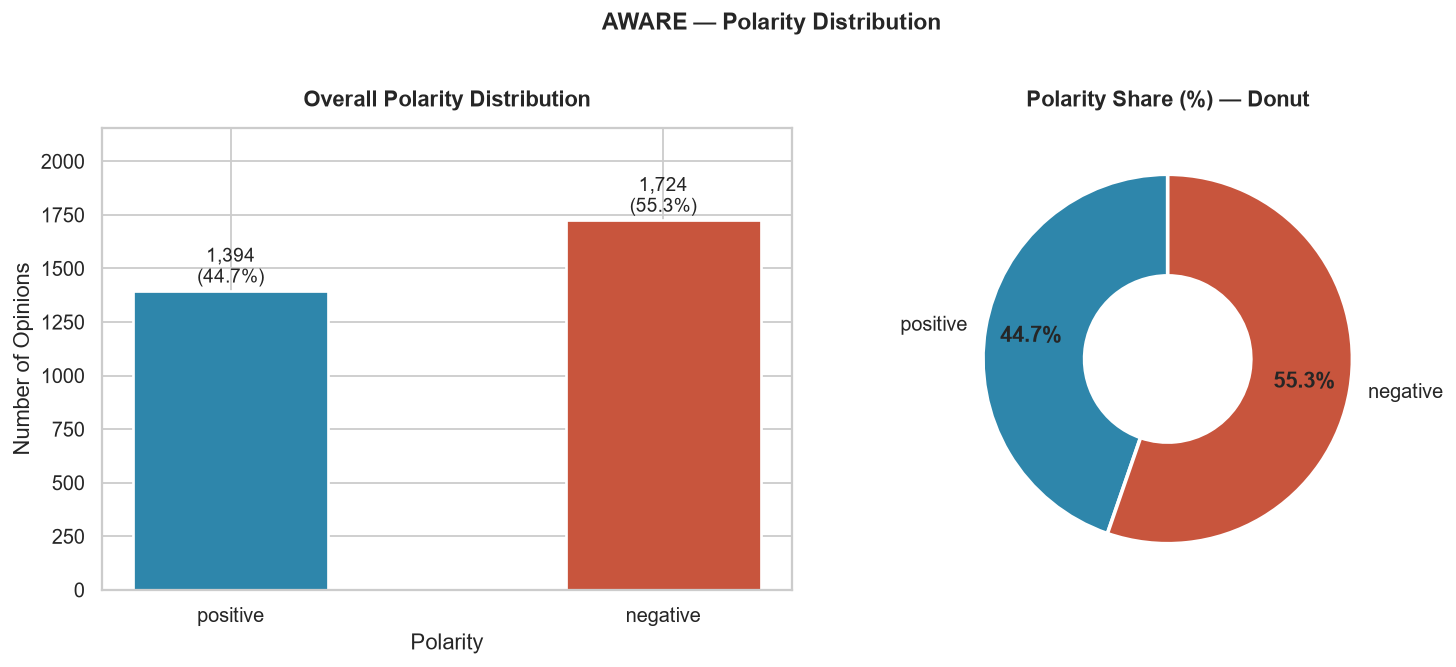

⚠️  Dataset chỉ có 2 classes: positive & negative (không có neutral).
   Imbalance ratio positive:negative = 1394:1724 (0.81:1)


In [58]:
# ── Cell 8: Phân bố polarity tổng thể ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pol_counts = df['polarity'].value_counts().reindex(['positive', 'negative'])

# Bar chart
bars = axes[0].bar(
    pol_counts.index, pol_counts.values,
    color=[SENTIMENT_COLORS[p] for p in pol_counts.index],
    edgecolor='white', linewidth=1.5, width=0.45
)
axes[0].set_title('Overall Polarity Distribution', fontweight='bold', pad=12)
axes[0].set_ylabel('Number of Opinions')
axes[0].set_xlabel('Polarity')
for bar, val in zip(bars, pol_counts.values):
    pct = val / pol_counts.sum() * 100
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
                 f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=10.5)
axes[0].set_ylim(0, pol_counts.max() * 1.25)

# Donut chart
wedges, _, autotexts = axes[1].pie(
    pol_counts.values,
    labels=pol_counts.index,
    colors=[SENTIMENT_COLORS[p] for p in pol_counts.index],
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(width=0.55, edgecolor='white', linewidth=2)
)
for t in autotexts:
    t.set_fontsize(12); t.set_fontweight('bold')
axes[1].set_title('Polarity Share (%) — Donut', fontweight='bold', pad=12)

plt.suptitle('AWARE — Polarity Distribution', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'⚠️  Dataset chỉ có 2 classes: positive & negative (không có neutral).')
print(f'   Imbalance ratio positive:negative = '
      f'{pol_counts["positive"]}:{pol_counts["negative"]} '
      f'({pol_counts["positive"]/pol_counts["negative"]:.2f}:1)')

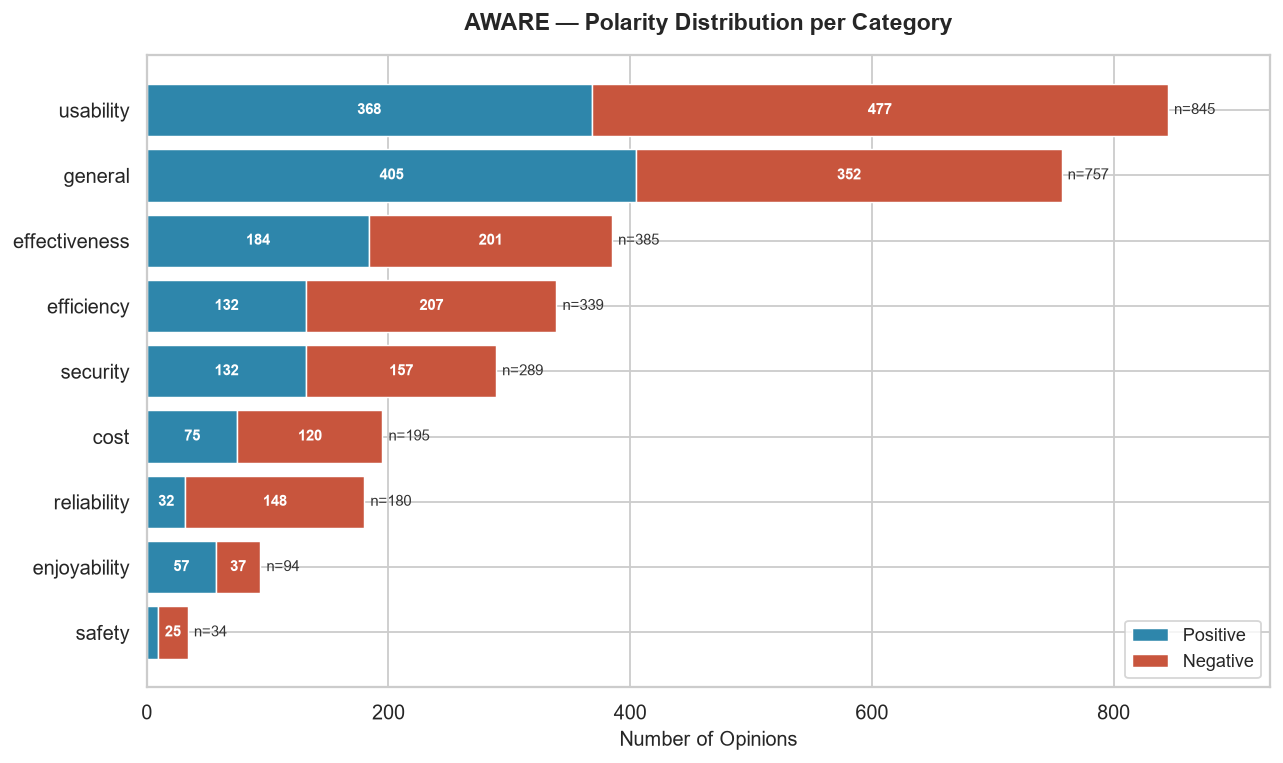

In [59]:
# ── Cell 9: Phân bố polarity theo category ────────────────────────────────
cat_pol = (
    df.groupby(['category', 'polarity'])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=['positive', 'negative'], fill_value=0)
)
cat_pol = cat_pol.loc[cat_pol.sum(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(10, 6))
bottom = np.zeros(len(cat_pol))

for pol in ['positive', 'negative']:
    vals = cat_pol[pol].values
    bars = ax.barh(cat_pol.index, vals, left=bottom,
                   color=SENTIMENT_COLORS[pol], label=pol.capitalize(),
                   edgecolor='white', linewidth=0.8)
    for i, (bar, v) in enumerate(zip(bars, vals)):
        if v > 15:
            ax.text(bottom[i] + v / 2, i, str(v),
                    ha='center', va='center', fontsize=8.5,
                    color='white', fontweight='bold')
    bottom += vals

ax.set_xlabel('Number of Opinions', fontsize=11)
ax.set_title('AWARE — Polarity Distribution per Category', fontsize=13, fontweight='bold', pad=14)
ax.legend(loc='lower right', fontsize=10)
ax.set_xlim(0, bottom.max() * 1.1)
for i, total in enumerate(bottom):
    ax.text(total + 5, i, f'n={int(total)}', va='center', fontsize=8.5, color='#333')

plt.tight_layout()
plt.show()

### 2.2 Phân bố theo app

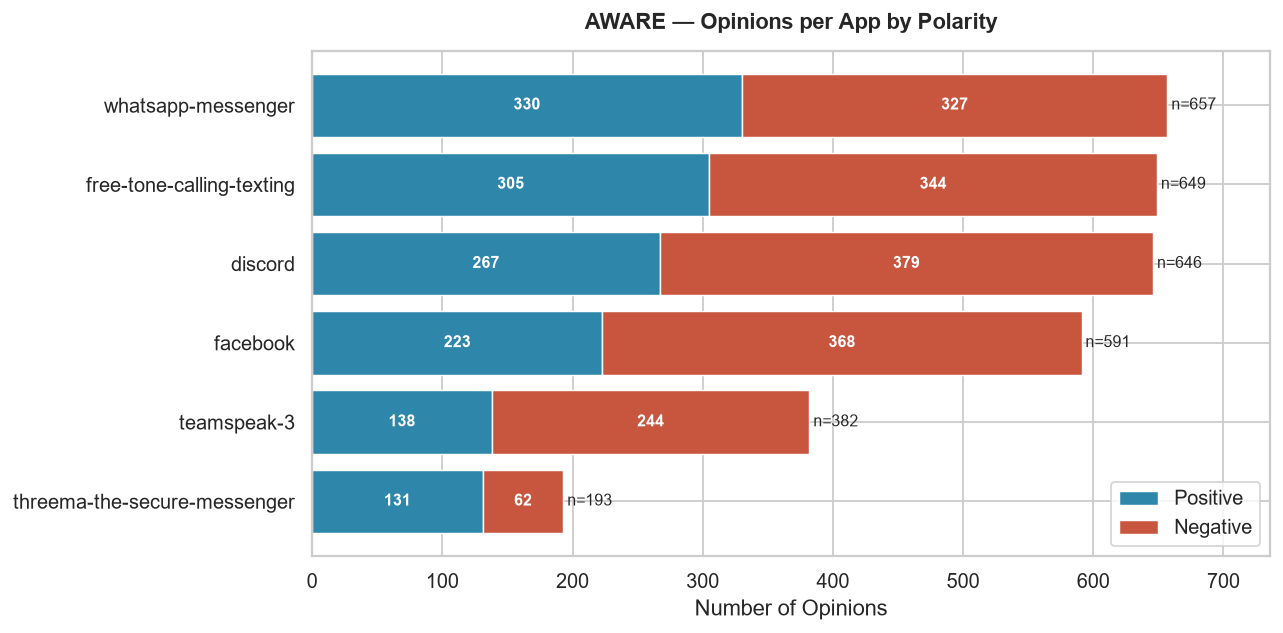

In [60]:
# ── Cell 10: Số opinion theo app và polarity ──────────────────────────────
app_pol = (
    df.groupby(['app', 'polarity'])
      .size()
      .unstack(fill_value=0)
      .reindex(columns=['positive', 'negative'], fill_value=0)
)
app_pol = app_pol.loc[app_pol.sum(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(app_pol))
for pol in ['positive', 'negative']:
    vals = app_pol[pol].values
    ax.barh(app_pol.index, vals, left=bottom,
            color=SENTIMENT_COLORS[pol], label=pol.capitalize(),
            edgecolor='white', linewidth=0.8)
    for i, v in enumerate(vals):
        if v > 20:
            ax.text(bottom[i] + v/2, i, str(v), ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    bottom += vals

for i, total in enumerate(bottom):
    ax.text(total + 3, i, f'n={int(total)}', va='center', fontsize=9)
ax.set_xlabel('Number of Opinions')
ax.set_title('AWARE — Opinions per App by Polarity', fontweight='bold', pad=12)
ax.legend(loc='lower right')
ax.set_xlim(0, bottom.max() * 1.12)
plt.tight_layout()
plt.show()

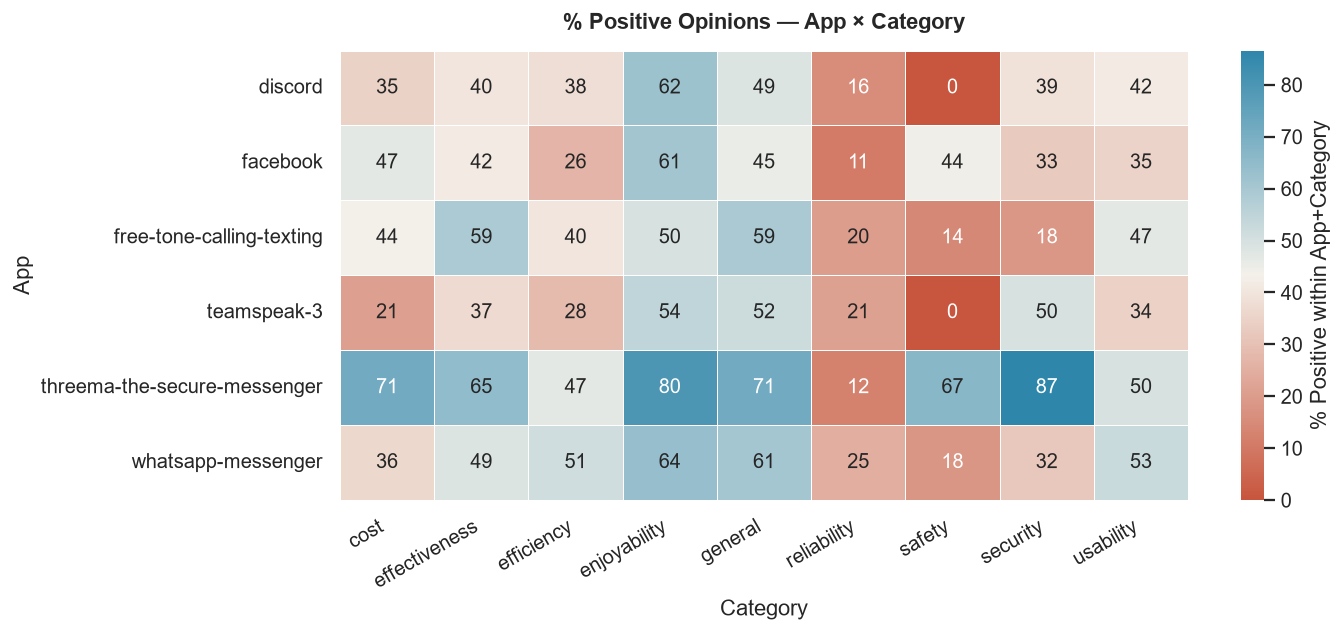

💡 Màu xanh = phần lớn opinions positive; màu đỏ = phần lớn negative.
   Heatmap này giúp xác định app nào/category nào cần cải thiện nhất.


In [61]:
# ── Cell 11: Heatmap tỉ lệ positive theo App × Category ───────────────────
cat_app = (
    df[df['polarity'] == 'positive']
    .groupby(['app', 'category'])
    .size()
    .unstack(fill_value=0)
)
# Normalize per row (per app)
cat_app_total = df.groupby(['app', 'category']).size().unstack(fill_value=0)
cat_app_pct = (cat_app / cat_app_total * 100).fillna(0).round(1)

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(
    cat_app_pct,
    annot=True, fmt='.0f', cmap=DIV_CMAP,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': '% Positive within App+Category'},
    ax=ax
)
ax.set_title('% Positive Opinions — App × Category', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Category'); ax.set_ylabel('App')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

print('💡 Màu xanh = phần lớn opinions positive; màu đỏ = phần lớn negative.')
print('   Heatmap này giúp xác định app nào/category nào cần cải thiện nhất.')

### 2.3 Độ dài câu
Histogram tính theo opinion (mỗi hàng một lần) và tách theo polarity; thống kê mô tả có thêm p95.

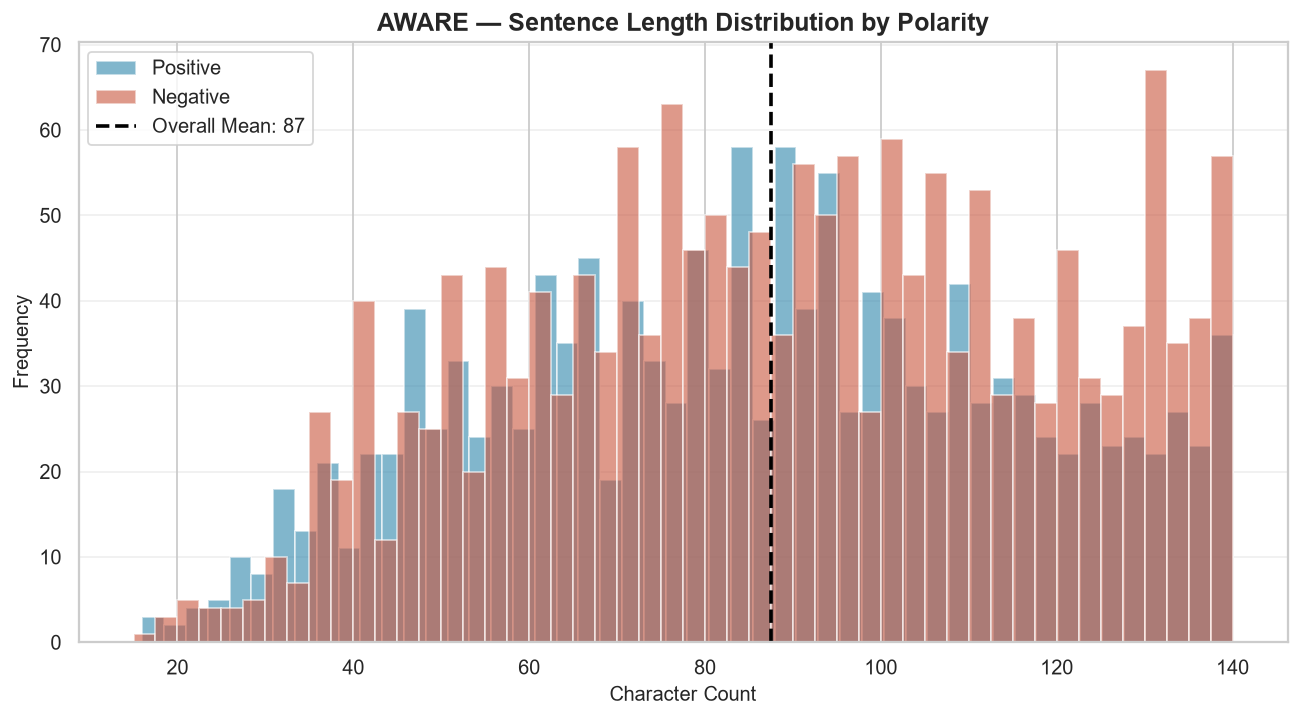

In [62]:
# ── Cell 12: Phân bố độ dài câu theo polarity ─────────────────────────────
plt.figure(figsize=(12, 6))

for pol, color in SENTIMENT_COLORS.items():
    plt.hist(
        df[df['polarity'] == pol]['text_len'],
        bins=50, alpha=0.6, color=color,
        label=pol.capitalize(), edgecolor='white'
    )

mean_len = df['text_len'].mean()
plt.axvline(mean_len, color='black', linestyle='--', linewidth=2, label=f'Overall Mean: {mean_len:.0f}')

plt.title('AWARE — Sentence Length Distribution by Polarity', fontsize=14, fontweight='bold')
plt.xlabel('Character Count', fontsize=11)
plt.ylabel('Frequency', fontsize=11)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

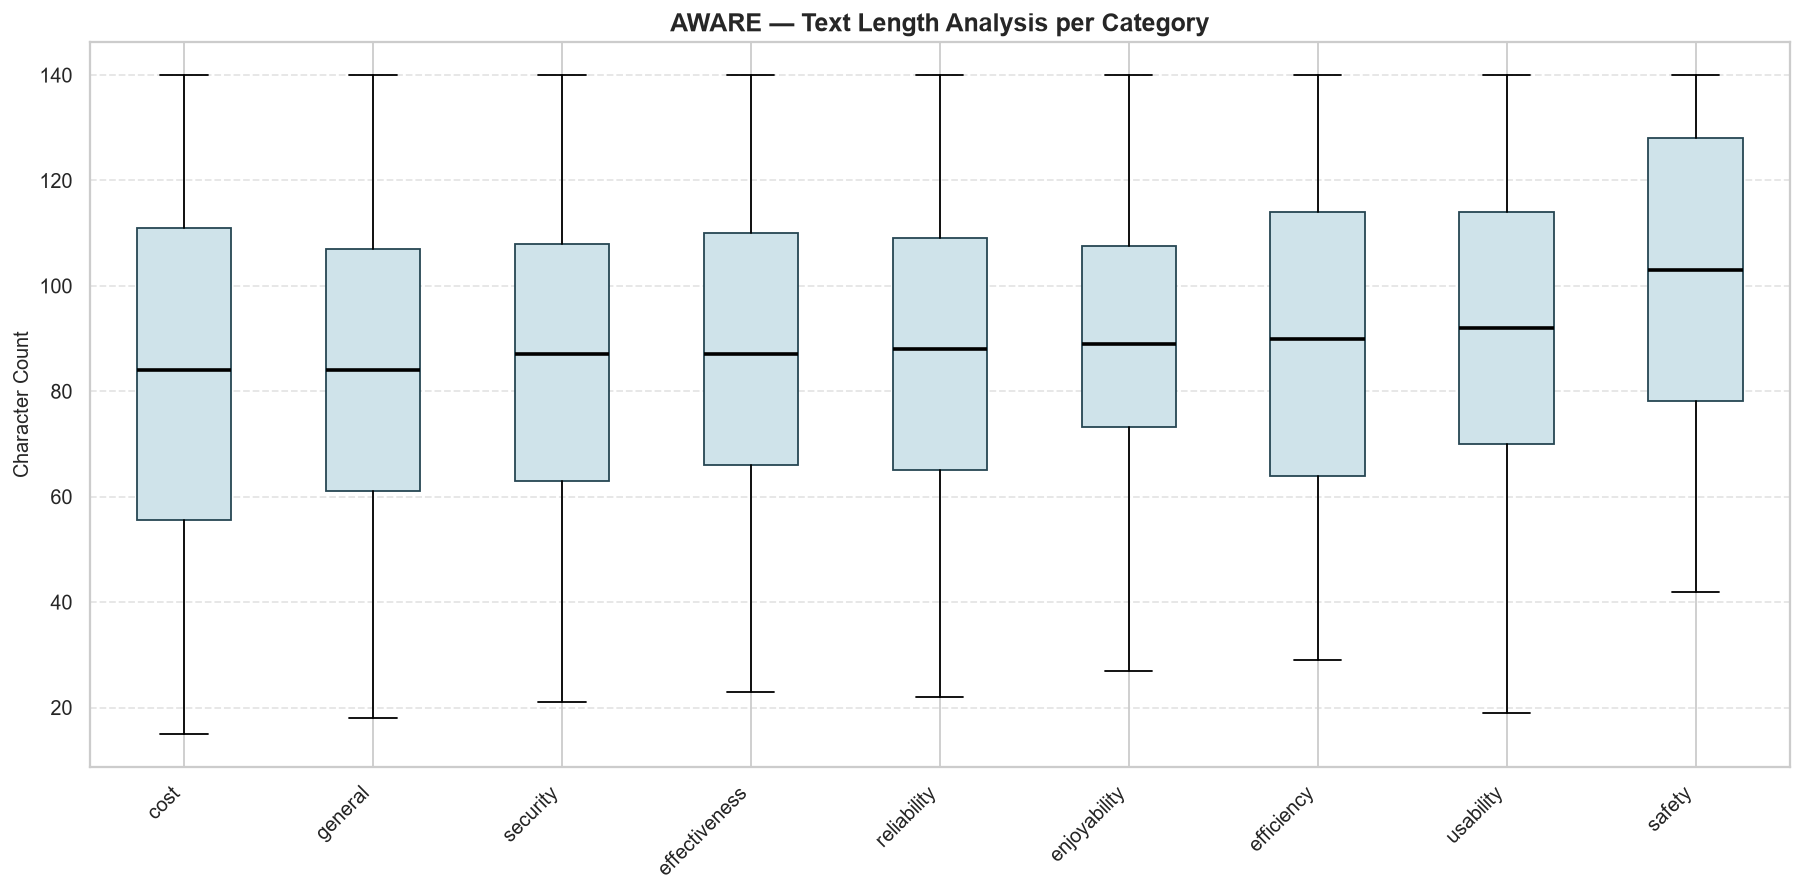

📏 Detailed Statistics by Polarity:


,count,mean,std,min,25%,50%,75%,95%,max
polarity,,,,,,,,,
negative,1724.0,89.2,29.8,15.0,67.0,90.0,113.0,135.0,140.0
positive,1394.0,85.4,29.6,16.0,63.0,86.0,108.0,134.0,140.0


In [63]:
# ── Cell 13: Độ dài câu theo category ─────────────────────────────────────
plt.figure(figsize=(14, 7))

# Sắp xếp category theo trung vị để biểu đồ có tính phân cấp
cat_order = df.groupby('category')['text_len'].median().sort_values().index.tolist()
bp_data = [df[df['category'] == cat]['text_len'].values for cat in cat_order]

bp = plt.boxplot(
    bp_data,
    tick_labels=cat_order, # Giữ nguyên tên gốc, không cắt ngắn vì đã có không gian
    patch_artist=True,
    vert=True,
    medianprops=dict(color='black', linewidth=2)
)

# Tô màu cho các box
for patch in bp['boxes']:
    patch.set_facecolor('#cfe3ea')
    patch.set_edgecolor(C_DARK)

plt.title('AWARE — Text Length Analysis per Category', fontsize=14, fontweight='bold')
plt.ylabel('Character Count', fontsize=11)
plt.xticks(rotation=45, ha='right') # Xoay nhãn 45 độ để dễ đọc
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Hiển thị bảng số liệu bổ trợ
print('📏 Detailed Statistics by Polarity:')
display(df.groupby('polarity')['text_len'].describe(percentiles=[.25, .5, .75, .95]).round(1))

### 2.4 Số khía cạnh trên mỗi câu

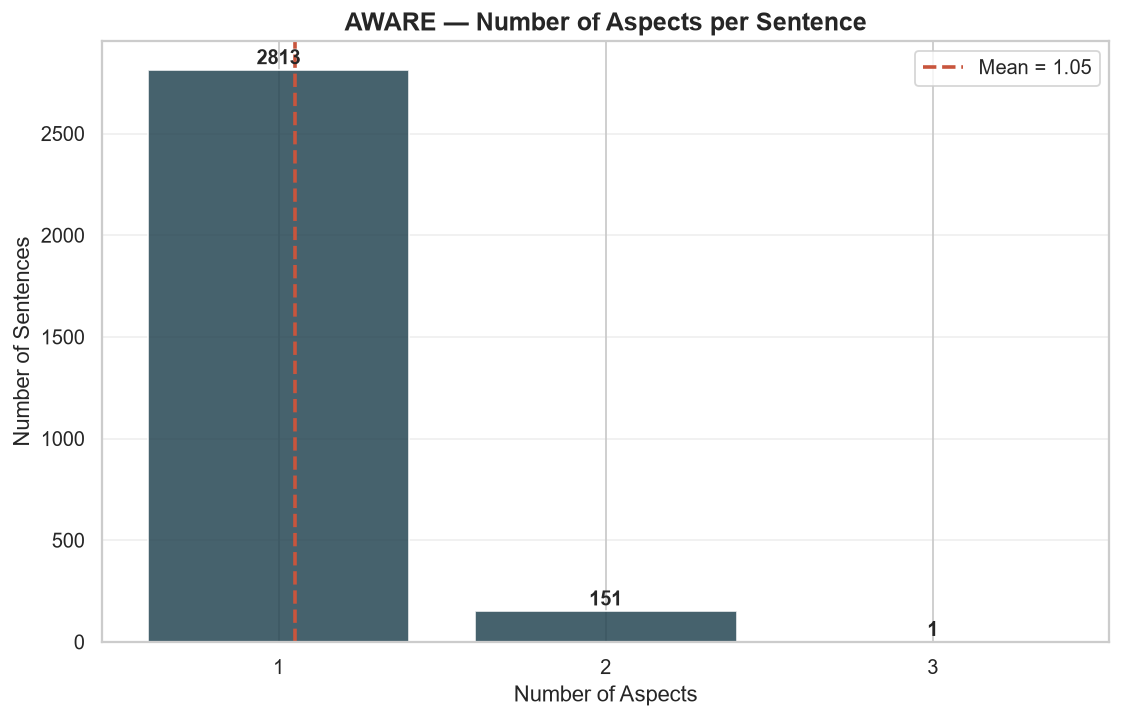

📐 Aspects per sentence: mean=1.05, max=3
   Sentences with >1 aspect: 152 (5.1%)


In [64]:
# ── Cell 14: Số aspect trên mỗi câu ───────────────────────────────────────
aspects_per_sent = df.groupby('sentence_id').size().reset_index(name='n_aspects')
vc = aspects_per_sent['n_aspects'].value_counts().sort_index()
avg = aspects_per_sent['n_aspects'].mean()

plt.figure(figsize=(10, 6))
plt.bar(vc.index, vc.values, color='#264653', edgecolor='white', alpha=0.85)
plt.axvline(avg, color='#C8553D', linestyle='--', linewidth=2, label=f'Mean = {avg:.2f}')

# Annotate values
for x, y in zip(vc.index, vc.values):
    plt.text(x, y + (max(vc.values)*0.01), str(y), ha='center', fontweight='bold')

plt.title('AWARE — Number of Aspects per Sentence', fontsize=14, fontweight='bold')
plt.xlabel('Number of Aspects')
plt.ylabel('Number of Sentences')
plt.xticks(vc.index)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

# Quick statistics
print(f'📐 Aspects per sentence: mean={avg:.2f}, max={aspects_per_sent["n_aspects"].max()}')
multi = aspects_per_sent[aspects_per_sent['n_aspects'] > 1]
print(f'   Sentences with >1 aspect: {len(multi):,} ({len(multi)/len(aspects_per_sent)*100:.1f}%)')

,số câu,có cực tính khác nhau,tỉ lệ (%)
nhóm,,,
2 aspect,151,26,17.2
3 aspect,1,0,0.0
Tất cả câu nhiều aspect,152,26,17.1


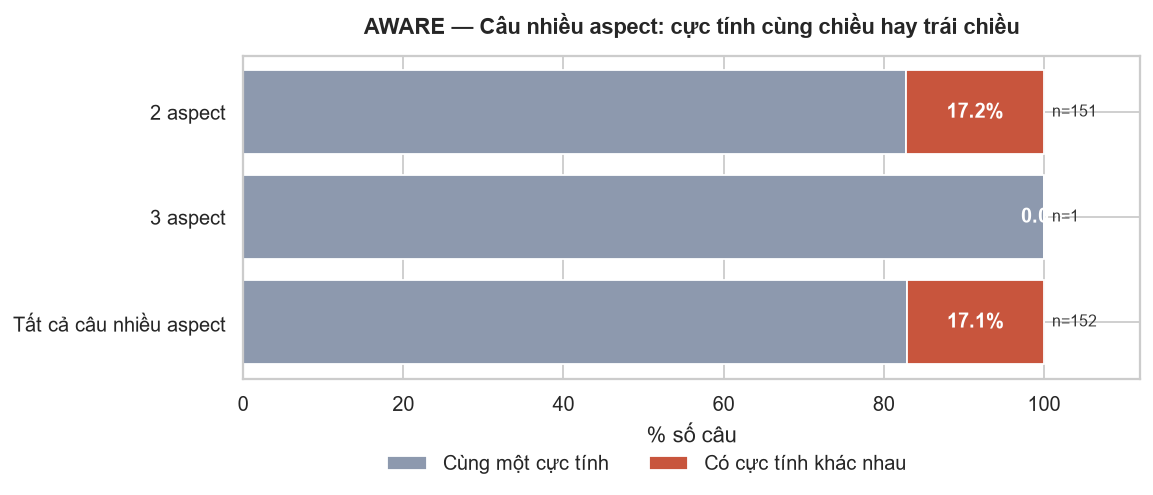

→ Trong 152 câu có nhiều aspect, 17.1% chứa cả positive lẫn negative.


In [65]:
# ── Cell 15: Câu nhiều aspect: các cực tính có trái chiều nhau không? ─────
sent = df.groupby('sentence_id').agg(n_aspects=('polarity', 'size'), n_pol=('polarity', 'nunique'))
multi = sent[sent['n_aspects'] > 1].copy()
multi['mixed'] = multi['n_pol'] > 1
multi['nhóm'] = multi['n_aspects'].clip(upper=4).map({2: '2 aspect', 3: '3 aspect', 4: '≥ 4 aspect'})

tab_mix = multi.groupby('nhóm')['mixed'].agg(['size', 'sum']).rename(columns={'size': 'số câu', 'sum': 'có cực tính khác nhau'})
tab_mix = tab_mix.reindex([g for g in ['2 aspect', '3 aspect', '≥ 4 aspect'] if g in tab_mix.index])
tab_mix.loc['Tất cả câu nhiều aspect'] = [len(multi), int(multi['mixed'].sum())]
tab_mix['tỉ lệ (%)'] = (tab_mix['có cực tính khác nhau'] / tab_mix['số câu'] * 100).round(1)
display(tab_mix)

fig, ax = plt.subplots(figsize=(9, 4.2))
pct = tab_mix['tỉ lệ (%)']
ax.barh(tab_mix.index, 100 - pct, color=C_GRAY, edgecolor='white', label='Cùng một cực tính')
ax.barh(tab_mix.index, pct, left=100 - pct, color=SENTIMENT_COLORS['negative'], edgecolor='white', label='Có cực tính khác nhau')
for i, (p, n) in enumerate(zip(pct, tab_mix['số câu'])):
    ax.text(100 - p / 2, i, f'{p:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    ax.text(101, i, f'n={n}', va='center', fontsize=9, color='#333')
ax.invert_yaxis(); ax.set_xlim(0, 112); ax.set_xlabel('% số câu')
ax.set_title('AWARE — Câu nhiều aspect: cực tính cùng chiều hay trái chiều', fontweight='bold', pad=12)
ax.legend(loc='lower center', bbox_to_anchor=(0.45, -0.35), ncol=2, frameon=False)
plt.tight_layout()
plt.show()
print(f"→ Trong {len(multi):,} câu có nhiều aspect, {multi['mixed'].mean() * 100:.1f}% chứa cả positive lẫn negative.")

### 2.5 Phân bố rating

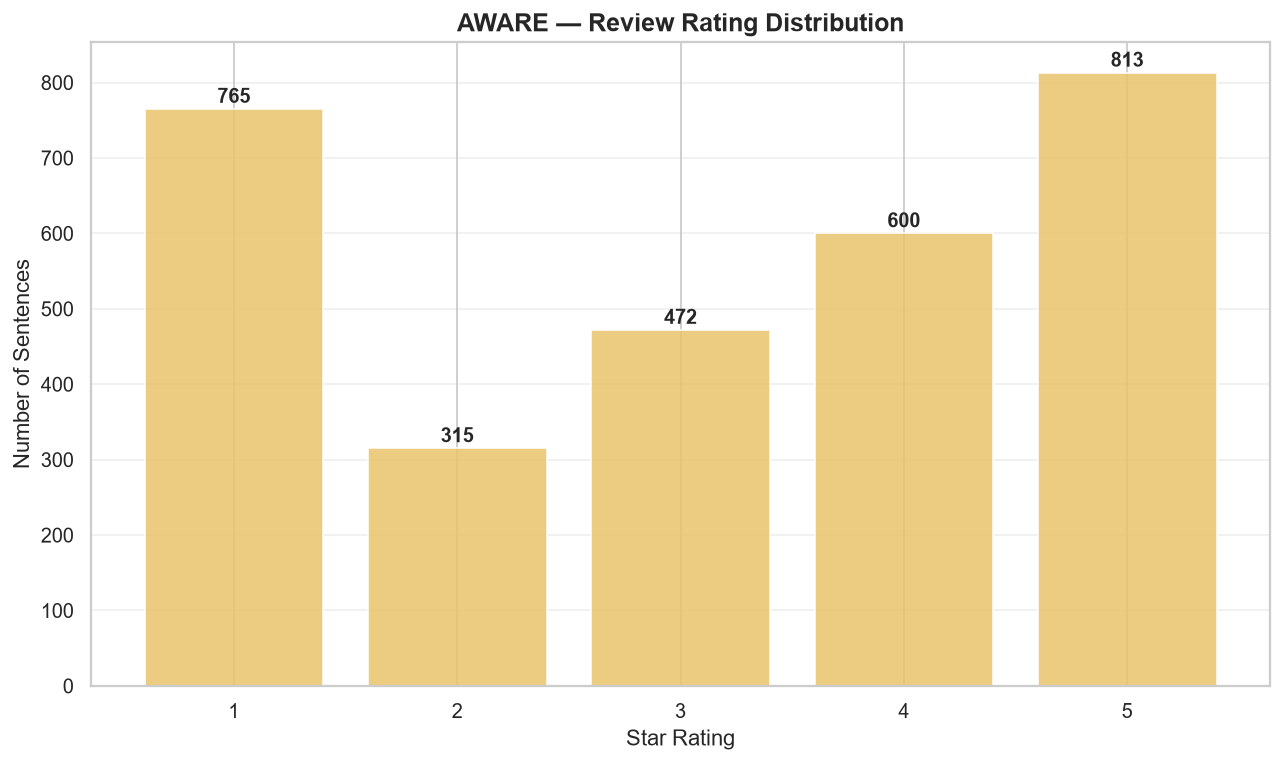

⭐ High Ratings (4-5 stars): 1,413 (47.7%)


In [66]:
# ── Cell 16: Phân bố rating của review ────────────────────────────────────
# Lấy rating duy nhất cho mỗi sentence_id
rating_counts = df.drop_duplicates('sentence_id')['rating'].value_counts().sort_index()

plt.figure(figsize=(10, 6))
plt.bar(rating_counts.index.astype(str), rating_counts.values,
        color='#E9C46A', edgecolor='white', alpha=0.85)

# Annotate values
for i, y in enumerate(rating_counts.values):
    plt.text(i, y + (max(rating_counts.values)*0.01), str(y), ha='center', fontweight='bold')

plt.title('AWARE — Review Rating Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Star Rating')
plt.ylabel('Number of Sentences')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Tính tỷ lệ rating 4-5 sao để xem độ bias của dữ liệu
high_rating = rating_counts.get(4, 0) + rating_counts.get(5, 0)
total_rating = rating_counts.sum()
print(f'⭐ High Ratings (4-5 stars): {high_rating:,} ({high_rating/total_rating*100:.1f}%)')

### 2.6 Target ngầm định
Opinion không có `term` (NaN) là ngầm định chặt; định nghĩa mở rộng tính thêm các term quá chung chung (`app`, `it`, `this`, ...). Hai định nghĩa được báo cáo cạnh nhau.

Implicit chặt (không có term): 18 / 3118 = 0.58%


,category,sentence,polarity
10,security,Especially not without the consent of the send...,negative
69,safety,Your app revelaed the biggest political scanda...,negative
88,general,I don't see any way it can be compromised and ...,negative
128,cost,and now even make payments to each other for a...,negative
178,efficiency,This prices yo me that it’s the WhatsApp app t...,negative
271,effectiveness,"If other people like this feature, maybe make ...",negative
377,general,Other than that it is the most special app in ...,positive
434,cost,Feels a bit like a waste of money now...,negative
470,general,"Initially, I installed this application in ord...",positive
591,usability,When I press the play button it starts over ab...,negative


is_implicit_strict    :  0.58%  (18 dòng)
is_implicit_extended  :  6.38%  (199 dòng)

is_implicit_extended
Explicit              93.62
Implicit (mở rộng)     6.38


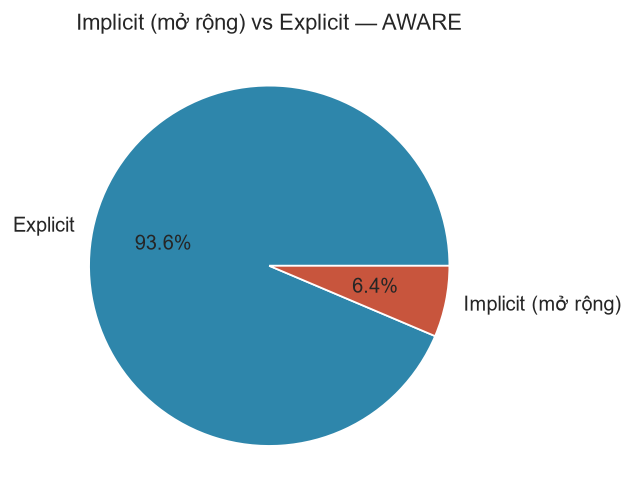

In [67]:
# ── Cell 17: Target ngầm định (chặt và mở rộng) ───────────────────────────
implicit_strict = df[df['term'].isna()]
print(f"Implicit chặt (không có term): {len(implicit_strict)} / {len(df)} = {len(implicit_strict)/len(df)*100:.2f}%")
display(implicit_strict[['category', 'sentence', 'polarity']].head(10))

# Định nghĩa MỞ RỘNG: term chỉ là từ chung chung (không cho biết đối tượng cụ thể)
generic_terms = {'app', 'version', 'update', 'it', 'this', 'that', 'thing'}
term_l = df['term'].astype(str).str.lower()
df['is_implicit_strict']   = df['term'].isna()
df['is_implicit_extended'] = df['term'].isna() | term_l.isin(generic_terms)
for col in ('is_implicit_strict', 'is_implicit_extended'):
    print(f"{col:<22}: {df[col].mean()*100:5.2f}%  ({int(df[col].sum())} dòng)")

dist = df['is_implicit_extended'].map({True: 'Implicit (mở rộng)', False: 'Explicit'}).value_counts(normalize=True) * 100
print(); print(dist.round(2).to_string())
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(dist.values, labels=dist.index, autopct='%1.1f%%', colors=[{'Explicit': '#2E86AB', 'Implicit (mở rộng)': '#C8553D'}[l] for l in dist.index])
ax.set_title('Implicit (mở rộng) vs Explicit — AWARE'); plt.show()

### 2.7 Biểu đồ tương tác

In [68]:
# ── Cell 18: Treemap — App → Category → Polarity ──────────────────────────
hier = df.groupby(['app', 'category', 'polarity']).size().reset_index(name='count')

fig = px.treemap(
    hier, path=['app', 'category', 'polarity'],
    values='count',
    color='polarity',
    color_discrete_map={
        'positive': '#2E86AB',
        'negative': '#C8553D',
        '(?)': '#8D99AE'
    },
    title='AWARE — Label Hierarchy: App → Category → Polarity'
)
fig.update_layout(height=580)
fig.update_traces(textinfo='label+value')
fig.show()
print('💡 Click để drill down: App → Category → Polarity.')

💡 Click để drill down: App → Category → Polarity.


In [69]:
# ── Cell 19: Sankey — Dòng opinion Category → Polarity ────────────────────
sankey_data = df.groupby(['category', 'polarity']).size().reset_index(name='count')
cats = sorted(sankey_data['category'].unique())
pols = sorted(sankey_data['polarity'].unique())
nodes = cats + pols

source = [nodes.index(r['category']) for _, r in sankey_data.iterrows()]
target = [nodes.index(r['polarity'])  for _, r in sankey_data.iterrows()]
value  = sankey_data['count'].tolist()

node_colors = (
    ['#264653'] * len(cats) +
    ['#2E86AB' if p == 'positive' else '#C8553D' for p in pols]
)

fig = go.Figure(go.Sankey(
    node=dict(
        pad=15, thickness=20,
        line=dict(color='black', width=0.5),
        label=nodes,
        color=node_colors
    ),
    link=dict(
        source=source, target=target, value=value,
        color=['rgba(46,134,171,0.35)' if pols[t - len(cats)] == 'positive'
               else 'rgba(200,85,61,0.35)' for t in target]
    )
))
fig.update_layout(
    title_text='AWARE — Opinion Flow: Category → Polarity',
    font_size=11, height=500
)
fig.show()

---
## 🔍 Bước 3 — Trích xuất Ví dụ & Minh hoạ Cơ chế Mapping

In [70]:
# ── Cell 20: Ví dụ ngẫu nhiên theo category × polarity ────────────────────
def show_random_examples(df: pd.DataFrame, n_per_cat: int = 1, seed: int = 42) -> pd.DataFrame:
    """Lấy n_per_cat ví dụ ngẫu nhiên cho mỗi (category, polarity) combo."""
    samples = []
    for (cat, pol), grp in df.groupby(['category', 'polarity']):
        n = min(n_per_cat, len(grp))
        chosen = grp.sample(n, random_state=seed)
        for _, row in chosen.iterrows():
            samples.append({
                'App': row['app'],
                'Category': cat,
                'Polarity': pol,
                'Example Sentence': row['sentence'][:130] + ('…' if len(row['sentence']) > 130 else '')
            })
    return pd.DataFrame(samples)

examples_df = show_random_examples(df, n_per_cat=1, seed=21)
print(f'📄 Random examples — {len(examples_df)} rows (1 per category×polarity combo):')
display(
    examples_df.style
    .map(lambda v: f'color: {SENTIMENT_COLORS.get(v, "black")}; font-weight:bold',
              subset=['Polarity'])
    .set_properties(**{'text-align': 'left', 'font-size': '11px'})
    .set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}])
)

📄 Random examples — 18 rows (1 per category×polarity combo):


,App,Category,Polarity,Example Sentence
0,teamspeak-3,cost,negative,Errors New update is pretty cool though but definitely not worth my money
1,threema-the-secure-messenger,cost,positive,"With all the privacy issues around, it is worth the money….."
2,teamspeak-3,effectiveness,negative,I have tried to connect to my guild chat sever and it always says out of date.
3,free-tone-calling-texting,effectiveness,positive,"Highly recommended if you want to receive calls without a phone account, or in areas with poor reception."
4,free-tone-calling-texting,efficiency,negative,The only thing I would try and fix is the speed of the phone calls and the speed and connectivity of the text messages..
5,threema-the-secure-messenger,efficiency,positive,"You can send text, audio, video."
6,facebook,enjoyability,negative,"Seriously, they need to add a setting where it blocks every game notification request PERIOD."
7,facebook,enjoyability,positive,Now every single picture I post as a cover photo is aligned wack.
8,free-tone-calling-texting,general,negative,"Also, beware of the talking ads: there are obnoxiously loud ads the talk though my phone speakers even when it's muted."
9,facebook,general,positive,It's beyond me that this app has changed the world and made history... And has only 3 stars.


In [71]:
# ── Cell 21: Hàm tra cứu ví dụ theo category và app ───────────────────────
def get_examples(df: pd.DataFrame, category: str, app: str = None,
                 n: int = 3, seed: int = 0) -> None:
    """
    In ra n ví dụ cho một category (và optionally một app) cụ thể.
    """
    subset = df[df['category'] == category]
    if app:
        subset = subset[subset['app'] == app]
    if subset.empty:
        print(f'Không tìm thấy: category={category}, app={app}')
        return

    title = f'[{category}]' + (f' | App: {app}' if app else '')
    print(f'\n── {title} ── ({len(subset)} opinions) ──')

    for pol in ['positive', 'negative']:
        pool = subset[subset['polarity'] == pol]
        if pool.empty:
            continue
        sample = pool.sample(min(n, len(pool)), random_state=seed)
        icon = {'positive': '✅', 'negative': '❌'}[pol]
        print(f'\n  {icon} {pol.upper()} ({len(pool)} total):')
        for i, (_, row) in enumerate(sample.iterrows(), 1):
            print(f'    {i}. [{row["app"]}] "{row["sentence"]}"')

# Demo
get_examples(df, 'usability', n=2)
get_examples(df, 'effectiveness', n=2)
get_examples(df, 'reliability', n=2)


── [usability] ── (845 opinions) ──

  ✅ POSITIVE (368 total):
    1. [discord] "I’ve been using Discord for like, forever now, and this new mobile interface is cool I guess."
    2. [free-tone-calling-texting] "Rather, I have a DUMB phone, that does all that I need, with respect to voice communications."

  ❌ NEGATIVE (477 total):
    1. [discord] "The new text box is counter intuitive."
    2. [discord] "Now it’s stuck on normal audio and I can’t switch to speaker."

── [effectiveness] ── (385 opinions) ──

  ✅ POSITIVE (184 total):
    1. [teamspeak-3] "You simply can't edit server groups on the iOS device."
    2. [facebook] "If someone would actually open my account or take the time to respond I would gladly rate higher."

  ❌ NEGATIVE (201 total):
    1. [teamspeak-3] "Up until now the audio volumes have been extremely low, and it was hard to hear if you’re not in a quiet area."
    2. [whatsapp-messenger] "and the pin placement while sending a location is not accurate."

── [re

In [72]:
# ── Cell 22: Minh hoạ cơ chế ABSA Mapping Logic ───────────────────────────
print('=' * 68)
print('   ABSA MAPPING LOGIC — ILLUSTRATION (AWARE)')
print('   (Các câu dưới đây do nhóm TỰ SOẠN để minh hoạ, KHÔNG lấy từ dữ liệu AWARE.)')
print('=' * 68)

mapping_examples = [
    {
        'sentence': 'The app is super easy to use and intuitive.',
        'aspect_term': 'app',
        'category': 'usability',
        'polarity': 'positive',
        'reasoning': '"easy to use", "intuitive" → positive về khả năng sử dụng'
    },
    {
        'sentence': 'The interface is confusing and hard to navigate.',
        'aspect_term': 'interface',
        'category': 'usability',
        'polarity': 'negative',
        'reasoning': '"confusing", "hard to navigate" → negative về usability'
    },
    {
        'sentence': 'Calls drop all the time, very unreliable.',
        'aspect_term': 'calls',
        'category': 'reliability',
        'polarity': 'negative',
        'reasoning': '"drop all the time" → negative về reliability'
    },
    {
        'sentence': 'Messages are always delivered instantly without fail.',
        'aspect_term': 'messages',
        'category': 'reliability',
        'polarity': 'positive',
        'reasoning': '"always delivered instantly" → positive về reliability'
    },
    {
        'sentence': 'End-to-end encryption gives me peace of mind.',
        'aspect_term': 'encryption',
        'category': 'security',
        'polarity': 'positive',
        'reasoning': '"peace of mind" từ encryption → positive về security'
    },
    {
        'sentence': 'The app drains my battery so fast.',
        'aspect_term': 'app',
        'category': 'efficiency',
        'polarity': 'negative',
        'reasoning': '"drains battery" → negative về efficiency'
    },
]

for i, ex in enumerate(mapping_examples, 1):
    icon = {'positive': '✅', 'negative': '❌'}[ex['polarity']]
    print(f'\nExample {i}:')
    print(f'  📝 Sentence    : "{ex["sentence"]}"')
    print(f'  🎯 Aspect Term : [{ex["aspect_term"]}]')
    print(f'  🏷️  Category   : {ex["category"]}')
    print(f'  {icon} Polarity   : {ex["polarity"].upper()}')
    print(f'  💡 Reasoning   : {ex["reasoning"]}')

print('\n' + '=' * 68)
print('KEY INSIGHT: AWARE dùng functional categories (usability,')
print('effectiveness, reliability...) thay vì entity-based như Res16.')
print('Model phải hiểu ngữ nghĩa chức năng của ứng dụng.')
print('=' * 68)

   ABSA MAPPING LOGIC — ILLUSTRATION (AWARE)
   (Các câu dưới đây do nhóm TỰ SOẠN để minh hoạ, KHÔNG lấy từ dữ liệu AWARE.)

Example 1:
  📝 Sentence    : "The app is super easy to use and intuitive."
  🎯 Aspect Term : [app]
  🏷️  Category   : usability
  ✅ Polarity   : POSITIVE
  💡 Reasoning   : "easy to use", "intuitive" → positive về khả năng sử dụng

Example 2:
  📝 Sentence    : "The interface is confusing and hard to navigate."
  🎯 Aspect Term : [interface]
  🏷️  Category   : usability
  ❌ Polarity   : NEGATIVE
  💡 Reasoning   : "confusing", "hard to navigate" → negative về usability

Example 3:
  📝 Sentence    : "Calls drop all the time, very unreliable."
  🎯 Aspect Term : [calls]
  🏷️  Category   : reliability
  ❌ Polarity   : NEGATIVE
  💡 Reasoning   : "drop all the time" → negative về reliability

Example 4:
  📝 Sentence    : "Messages are always delivered instantly without fail."
  🎯 Aspect Term : [messages]
  🏷️  Category   : reliability
  ✅ Polarity   : POSITIVE
  💡 Reasonin

---
## 📋 Bước 4 — So sánh với Res16 và Tổng kết

In [73]:
# ── Cell 23: So sánh cấu trúc AWARE và Res16 ──────────────────────────────
print('=' * 60)
print('   AWARE vs RES16 — STRUCTURAL COMPARISON')
print('=' * 60)
comparison = pd.DataFrame({
    'Property': [
        'Domain',
        'Format',
        'Total opinions',
        'Category schema',
        'No. of categories',
        'Polarity classes',
        'No. of polarities',
        'Has neutral class',
        'Train/Test split',
        'Multiple aspects per sentence'
    ],
    'AWARE': [
        'Social networking app reviews',
        'Flat / Tidy (1 row = 1 opinion)',
        f'{len(df):,}',
        'Functional (usability, reliability...)',
        f'{df["category"].nunique()}',
        'positive / negative',
        '2',
        'No',
        'Single file',
        f'{(df.groupby("sentence_id").size() > 1).mean()*100:.1f}%'
    ],
    'Res16': [
        'Restaurant reviews',
        'XML lồng nhau (Review → sentence → Opinion), làm phẳng bằng parse_xml',
        '3,366',
        'Entity#Attribute (FOOD#QUALITY...)',
        '12',
        'positive / negative / neutral',
        '3',
        'Yes',
        'Separate train & test files',
        '32.0% (tính ở notebook 01)'
    ]
})
display(comparison.style.hide(axis='index')
        .set_properties(**{'text-align': 'left', 'font-size': '11px'})
        .set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}]))

   AWARE vs RES16 — STRUCTURAL COMPARISON


Property,AWARE,Res16
Domain,Social networking app reviews,Restaurant reviews
Format,Flat / Tidy (1 row = 1 opinion),"XML lồng nhau (Review → sentence → Opinion), làm phẳng bằng parse_xml"
Total opinions,"3,118","3,366"
Category schema,"Functional (usability, reliability...)",Entity#Attribute (FOOD#QUALITY...)
No. of categories,9,12
Polarity classes,positive / negative,positive / negative / neutral
No. of polarities,2,3
Has neutral class,No,Yes
Train/Test split,Single file,Separate train & test files
Multiple aspects per sentence,5.1%,32.0% (tính ở notebook 01)


In [74]:
# ── Cell 24: Comprehensive Summary Table ──────────────────────────────────
print('=' * 60)
print('   AWARE DATASET — EDA SUMMARY REPORT')
print('=' * 60)

print(f'\n📦 DATASET OVERVIEW')
print(f'   Total opinions                 : {len(df):,}')
print(f'   Unique reviews                 : {df["review_id"].nunique():,}')
print(f'   Unique sentences               : {df["sentence_id"].nunique():,}')
print(f'   Unique apps                    : {df["app"].nunique()}')

print(f'\n🏷️  LABEL SPACE')
print(f'   Unique categories              : {df["category"].nunique()}')
print(f'   Unique polarities              : {df["polarity"].nunique()}')
print(f'   Theoretical combos (CxP)       : {df["category"].nunique() * df["polarity"].nunique()}')
print(f'   Actual observed combos         : {df.groupby(["category","polarity"]).ngroups}')

pol_dist = df['polarity'].value_counts(normalize=True) * 100
print(f'\n📊 POLARITY DISTRIBUTION')
for pol in ['positive', 'negative']:
    count = df['polarity'].value_counts()[pol]
    pct   = pol_dist[pol]
    print(f'   {pol.capitalize():<12}: {count:,} ({pct:.1f}%)')

asp_avg = df.groupby('sentence_id').size().mean()
print(f'\n📐 TEXT & ASPECT STATS')
sent_len = df.drop_duplicates('sentence_id')['text_len']
print(f'   Mean sentence length (chars)   : {sent_len.mean():.1f}')
print(f'   Median sentence length (chars) : {sent_len.median():.1f}')
print(f'   Mean aspects per sentence      : {asp_avg:.2f}')
multi_pct = (df.groupby('sentence_id').size() > 1).mean() * 100
print(f'   Sentences with >1 aspect       : {multi_pct:.1f}%')
print(f'   ...trong đó có cực tính khác nhau : {multi["mixed"].mean() * 100:.1f}%')
print(f'   Implicit (chặt / mở rộng)      : {df["is_implicit_strict"].mean() * 100:.1f}% / {df["is_implicit_extended"].mean() * 100:.1f}%')

print(f'\n✅ DATA QUALITY')
print(f'   Missing category values        : {df["category"].isna().sum()}')
print(f'   Missing polarity values        : {df["polarity"].isna().sum()}')
print(f'   Missing sentence values        : {df["sentence"].isna().sum()}')

print('\n' + '=' * 60)
print('   Hoàn tất EDA AWARE (chỉ dùng để so sánh miền dữ liệu).')
print('=' * 60)

   AWARE DATASET — EDA SUMMARY REPORT

📦 DATASET OVERVIEW
   Total opinions                 : 3,118
   Unique reviews                 : 1,615
   Unique sentences               : 2,965
   Unique apps                    : 6

🏷️  LABEL SPACE
   Unique categories              : 9
   Unique polarities              : 2
   Theoretical combos (CxP)       : 18
   Actual observed combos         : 18

📊 POLARITY DISTRIBUTION
   Positive    : 1,394 (44.7%)
   Negative    : 1,724 (55.3%)

📐 TEXT & ASPECT STATS
   Mean sentence length (chars)   : 87.2
   Median sentence length (chars) : 88.0
   Mean aspects per sentence      : 1.05
   Sentences with >1 aspect       : 5.1%
   ...trong đó có cực tính khác nhau : 17.1%
   Implicit (chặt / mở rộng)      : 0.6% / 6.4%

✅ DATA QUALITY
   Missing category values        : 0
   Missing polarity values        : 0
   Missing sentence values        : 0

   Hoàn tất EDA AWARE (chỉ dùng để so sánh miền dữ liệu).


In [75]:
# ── Cell 25: (Tuỳ chọn) Export DataFrame đã làm sạch ──────────────────────
# df.to_csv('aware_cleaned.csv', index=False)
# print('✅ Exported to aware_cleaned.csv')
print('💾 Để export: bỏ comment dòng trên và chạy lại cell này.')
print(f'   Cleaned DataFrame trong biến `df` với shape {df.shape}')

💾 Để export: bỏ comment dòng trên và chạy lại cell này.
   Cleaned DataFrame trong biến `df` với shape (3118, 17)
